#Importamos librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
url = "https://drive.google.com/uc?id=1lVhGyuvo5Fe0B-ExzU9FTRtNprc1ENDO"

df = pd.read_csv(url)

df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


#Primeras observaciones

##Primeros y últimos valores de la base

In [ ]:
df.tail()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,15,1,1,1,1,1,6,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,15,1,1,19,1,1,10,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,12,1,1,1,22,27,10,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9,1,1,1,22,27,8,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,5,1,15,1,1,9,23,27,6,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [ ]:
df.shape

(4424, 35)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [ ]:
cuantitativas = [
    "Age at enrollment",
    *[
        columna for columna in df.columns
        if columna.startswith("Curricular units")
    ],
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]

display(df[cuantitativas].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00
Curricular units 2nd sem (credited),4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00
Curricular units 2nd sem (enrolled),4424.0,6.23,2.20,0.00,5.00,6.00,7.00,23.00
Curricular units 2nd sem (evaluations),4424.0,8.06,3.95,0.00,6.00,8.00,10.00,33.00


##Valores faltantes y duplicados

In [ ]:
print("Valores faltantes:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

Valores faltantes: 0
Filas duplicadas: 0


,Cantidad,Porcentaje
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


##Distribución de estudiantes que abandonaron y los que no

In [ ]:
distribucion = df["Target"].value_counts().to_frame("Cantidad")

distribucion["Porcentaje"] = (
    distribucion["Cantidad"] / len(df) * 100
).round(2)

display(distribucion)

,Cantidad,Porcentaje
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


#Preparación de datos

In [ ]:
# Variable objetivo:
# 1 = abandono
# 0 = sin abandono registrado (graduados e inscriptos)

y = df["Target"].map({
    "Dropout": 1,
    "Graduate": 0,
    "Enrolled": 0
})
print(y.value_counts().sort_index())

Target
0    3003
1    1421
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Primer escenario: excluimos las variables del segundo semestre.
columnas_1 = [
    columna for columna in df.columns
    if columna != "Target"
    and not columna.startswith("Curricular units 2nd sem")
]

X_1 = df[columnas_1].copy()

# Segundo escenario: incluimos ambos semestres.
X_2 = df.drop(columns="Target").copy()

# División común, conservando la proporción de abandono.
indices_train, indices_test = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_1 = X_1.loc[indices_train].copy()
X_test_1 = X_1.loc[indices_test].copy()

X_train_2 = X_2.loc[indices_train].copy()
X_test_2 = X_2.loc[indices_test].copy()

y_train = y.loc[indices_train].copy()
y_test = y.loc[indices_test].copy()

In [ ]:
dimensiones = pd.DataFrame({
    "Escenario": ["Primer semestre", "Ambos semestres"],
    "Estudiantes entrenamiento": [
        len(X_train_1), len(X_train_2)
    ],
    "Estudiantes prueba": [
        len(X_test_1), len(X_test_2)
    ],
    "Predictores": [
        X_train_1.shape[1], X_train_2.shape[1]
    ]
})

display(dimensiones)

proporciones = pd.DataFrame({
    "Base completa": y.value_counts(normalize=True),
    "Entrenamiento": y_train.value_counts(normalize=True),
    "Prueba": y_test.value_counts(normalize=True)
}).sort_index().mul(100)

proporciones.index = ["Sin abandono registrado", "Abandono"]

display(proporciones.round(2))

,Escenario,Estudiantes entrenamiento,Estudiantes prueba,Predictores
0,Primer semestre,3539,885,28
1,Ambos semestres,3539,885,34


,Base completa,Entrenamiento,Prueba
Sin abandono registrado,67.88,67.87,67.91
Abandono,32.12,32.13,32.09


##Revisión de valores extremos con Rango Intercuartílico

In [ ]:
resultados_extremos = []

for variable in cuantitativas:
    serie = X_train_2[variable]

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    ric = q3 - q1

    inferior = q1 - 1.5 * ric
    superior = q3 + 1.5 * ric

    señalados = (serie < inferior) | (serie > superior)

    resultados_extremos.append({
        "Variable": variable,
        "Límite inferior": inferior,
        "Límite superior": superior,
        "Cantidad señalada": int(señalados.sum()),
        "Porcentaje señalado": señalados.mean() * 100,
        "RIC cero": ric == 0
    })

tabla_extremos = pd.DataFrame(resultados_extremos)

display(
    tabla_extremos
    .sort_values("Porcentaje señalado", ascending=False)
    .round(2)
)

,Variable,Límite inferior,Límite superior,Cantidad señalada,Porcentaje señalado,RIC cero
11,Curricular units 2nd sem (grade),6.86,17.24,710,20.06,False
5,Curricular units 1st sem (grade),7.40,17.00,592,16.73,False
1,Curricular units 1st sem (credited),0.00,0.00,467,13.20,True
7,Curricular units 2nd sem (credited),0.00,0.00,422,11.92,True
0,Age at enrollment,10.00,34.00,340,9.61,False
2,Curricular units 1st sem (enrolled),2.00,10.00,329,9.30,False
8,Curricular units 2nd sem (enrolled),2.00,10.00,284,8.02,False
6,Curricular units 1st sem (without evaluations),0.00,0.00,235,6.64,True
12,Curricular units 2nd sem (without evaluations),0.00,0.00,215,6.08,True
4,Curricular units 1st sem (approved),-1.50,10.50,134,3.79,False


##Tipos de variables

In [ ]:
categoricas = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

binarias = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Conservamos Application order como predictor ordenado.
numericas = cuantitativas + ["Application order"]


print("Categóricas:", len(categoricas))
print("Binarias:", len(binarias))
print("Numéricas y ordenadas:", len(numericas))

Categóricas: 9
Binarias: 8
Numéricas y ordenadas: 17


#Preprocesamiento de datos

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def crear_preprocesador(columnas, escalar=False):
    # Seleccionamos las variables presentes en cada escenario.
    cat = [c for c in categoricas if c in columnas]
    num = [c for c in numericas if c in columnas]
    bin_ = [c for c in binarias if c in columnas]

    return ColumnTransformer(
        transformers=[
            (
                "categoricas",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                cat
            ),
            (
                "numericas",
                StandardScaler() if escalar else "passthrough",
                num
            ),
            (
                "binarias",
                "passthrough",
                bin_
            )
        ],
        remainder="drop"
    )

# Validación cruzada y métricas para comparar los distintos modelos

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Materializamos las particiones para compartirlas entre
# los cuatro modelos y los dos escenarios.
particiones_cv = list(cv.split(X_train_1, y_train))

metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

print("Cantidad de particiones:", len(particiones_cv))

Cantidad de particiones: 5


#Modelos de Aprendizaje Automático

##Random Forest (modelo base)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

resultados_rf = []

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    modelo_rf = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=False)
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=1
            )
        )
    ])

    evaluacion = cross_validate(
        modelo_rf,
        X_train,
        y_train,
        cv=particiones_cv,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        resultados_rf.append({
            "Escenario": escenario,
            "Métrica": metrica,
            "Media": valores.mean(),
            "Desvío entre particiones": valores.std(ddof=1)
        })

tabla_rf = pd.DataFrame(resultados_rf)

display(tabla_rf.round(4))

,Escenario,Métrica,Media,Desvío entre particiones
0,Primer semestre,accuracy,0.8468,0.0075
1,Primer semestre,precision,0.8371,0.0238
2,Primer semestre,recall,0.6508,0.0307
3,Primer semestre,f1,0.7317,0.0171
4,Primer semestre,roc_auc,0.8906,0.0104
5,Ambos semestres,accuracy,0.8680,0.0098
6,Ambos semestres,precision,0.8714,0.0186
7,Ambos semestres,recall,0.6913,0.0198
8,Ambos semestres,f1,0.7709,0.0178
9,Ambos semestres,roc_auc,0.9121,0.0102


##Gradient Boosting (modelo base)

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

resultados_gb = []

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    modelo_gb = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=False)
        ),
        (
            "modelo",
            GradientBoostingClassifier(random_state=42)
        )
    ])

    evaluacion = cross_validate(
        modelo_gb,
        X_train,
        y_train,
        cv=particiones_cv,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        resultados_gb.append({
            "Escenario": escenario,
            "Métrica": metrica,
            "Media": valores.mean(),
            "Desvío entre particiones": valores.std(ddof=1)
        })

tabla_gb = pd.DataFrame(resultados_gb)

display(tabla_gb.round(4))

,Escenario,Métrica,Media,Desvío entre particiones
0,Primer semestre,accuracy,0.8539,0.0057
1,Primer semestre,precision,0.8304,0.0221
2,Primer semestre,recall,0.6860,0.0114
3,Primer semestre,f1,0.7511,0.0077
4,Primer semestre,roc_auc,0.8963,0.0111
5,Ambos semestres,accuracy,0.8734,0.0077
6,Ambos semestres,precision,0.8559,0.0200
7,Ambos semestres,recall,0.7291,0.0132
8,Ambos semestres,f1,0.7873,0.0121
9,Ambos semestres,roc_auc,0.9125,0.0113


##KNN (modelo base)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

resultados_knn = []

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    modelo_knn = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=True)
        ),
        (
            "modelo",
            KNeighborsClassifier(n_neighbors=5)
        )
    ])

    evaluacion = cross_validate(
        modelo_knn,
        X_train,
        y_train,
        cv=particiones_cv,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        resultados_knn.append({
            "Escenario": escenario,
            "Métrica": metrica,
            "Media": valores.mean(),
            "Desvío entre particiones": valores.std(ddof=1)
        })

tabla_knn = pd.DataFrame(resultados_knn)

display(tabla_knn.round(4))

,Escenario,Métrica,Media,Desvío entre particiones
0,Primer semestre,accuracy,0.7954,0.0071
1,Primer semestre,precision,0.7880,0.0066
2,Primer semestre,recall,0.4969,0.0290
3,Primer semestre,f1,0.6091,0.0217
4,Primer semestre,roc_auc,0.8031,0.0087
5,Ambos semestres,accuracy,0.8251,0.0081
6,Ambos semestres,precision,0.8270,0.0275
7,Ambos semestres,recall,0.5769,0.0219
8,Ambos semestres,f1,0.6793,0.0166
9,Ambos semestres,roc_auc,0.8397,0.0094


##Regresión Logística (modelo base)

In [ ]:
from sklearn.linear_model import LogisticRegression

resultados_lr = []

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    modelo_lr = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=True)
        ),
        (
            "modelo",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ])

    evaluacion = cross_validate(
        modelo_lr,
        X_train,
        y_train,
        cv=particiones_cv,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        resultados_lr.append({
            "Escenario": escenario,
            "Métrica": metrica,
            "Media": valores.mean(),
            "Desvío entre particiones": valores.std(ddof=1)
        })

tabla_lr = pd.DataFrame(resultados_lr)

display(tabla_lr.round(4))

,Escenario,Métrica,Media,Desvío entre particiones
0,Primer semestre,accuracy,0.8587,0.0082
1,Primer semestre,precision,0.8320,0.0236
2,Primer semestre,recall,0.7027,0.0110
3,Primer semestre,f1,0.7617,0.0115
4,Primer semestre,roc_auc,0.9047,0.0069
5,Ambos semestres,accuracy,0.8754,0.0093
6,Ambos semestres,precision,0.8535,0.0310
7,Ambos semestres,recall,0.7405,0.0243
8,Ambos semestres,f1,0.7925,0.0143
9,Ambos semestres,roc_auc,0.9216,0.0096


##Comparación de modelos base

In [ ]:
resultados_base = pd.concat([
    tabla_rf.assign(Modelo="Random Forest"),
    tabla_gb.assign(Modelo="Gradient Boosting"),
    tabla_knn.assign(Modelo="KNN"),
    tabla_lr.assign(Modelo="Regresión Logística")
], ignore_index=True)

comparacion_base = resultados_base.pivot(
    index=["Escenario", "Modelo"],
    columns="Métrica",
    values="Media"
)

comparacion_base = comparacion_base[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
]

comparacion_base = comparacion_base.sort_values(
    ["Escenario", "f1"],
    ascending=[True, False]
)

display(comparacion_base.round(4))

Métrica                              accuracy  precision  recall      f1  \
Escenario       Modelo                                                     
Ambos semestres Regresión Logística    0.8754     0.8535  0.7405  0.7925   
                Gradient Boosting      0.8734     0.8559  0.7291  0.7873   
                Random Forest          0.8680     0.8714  0.6913  0.7709   
                KNN                    0.8251     0.8270  0.5769  0.6793   
Primer semestre Regresión Logística    0.8587     0.8320  0.7027  0.7617   
                Gradient Boosting      0.8539     0.8304  0.6860  0.7511   
                Random Forest          0.8468     0.8371  0.6508  0.7317   
                KNN                    0.7954     0.7880  0.4969  0.6091   

Métrica                              roc_auc  
Escenario       Modelo                        
Ambos semestres Regresión Logística   0.9216  
                Gradient Boosting     0.9125  
                Random Forest         0.9121  
                KNN                   0.8397  
Primer semestre Regresión Logística   0.9047  
                Gradient Boosting     0.8963  
                Random Forest         0.8906  
                KNN                   0.8031

#Optimización de hiperparámetros para cada modelo

##Regresión Logística (optimizado)

In [ ]:
from sklearn.model_selection import GridSearchCV

# Guardaremos las búsquedas para recuperar los modelos seleccionados.
busquedas_lr = {}
resultados_lr_opt = []

parametros_lr = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__class_weight": [None, "balanced"]
}

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    pipeline_lr = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=True)
        ),
        (
            "modelo",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ])

    busqueda = GridSearchCV(
        estimator=pipeline_lr,
        param_grid=parametros_lr,
        scoring=metricas,
        refit="f1",
        cv=particiones_cv,
        n_jobs=-1,
        error_score="raise"
    )

    busqueda.fit(X_train, y_train)
    busquedas_lr[escenario] = busqueda

    print(f"\n{escenario}")
    print("Mejores hiperparámetros:", busqueda.best_params_)

    indice = busqueda.best_index_

    for metrica in metricas:
        resultados_lr_opt.append({
            "Escenario": escenario,
            "Modelo": "Regresión Logística",
            "Métrica": metrica,
            "Media": busqueda.cv_results_[
                f"mean_test_{metrica}"
            ][indice]
        })

tabla_lr_opt = pd.DataFrame(resultados_lr_opt)

display(tabla_lr_opt.round(4))


Primer semestre
Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'}

Ambos semestres
Mejores hiperparámetros: {'modelo__C': 1, 'modelo__class_weight': None}


,Escenario,Modelo,Métrica,Media
0,Primer semestre,Regresión Logística,accuracy,0.8443
1,Primer semestre,Regresión Logística,precision,0.7422
2,Primer semestre,Regresión Logística,recall,0.7916
3,Primer semestre,Regresión Logística,f1,0.7657
4,Primer semestre,Regresión Logística,roc_auc,0.9029
5,Ambos semestres,Regresión Logística,accuracy,0.8754
6,Ambos semestres,Regresión Logística,precision,0.8535
7,Ambos semestres,Regresión Logística,recall,0.7405
8,Ambos semestres,Regresión Logística,f1,0.7925
9,Ambos semestres,Regresión Logística,roc_auc,0.9216


##Random Forest (optimizado)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

busquedas_rf = {}
resultados_rf_opt = []

parametros_rf = {
    "modelo__n_estimators": [200, 400, 600],
    "modelo__max_depth": [None, 5, 10, 20],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__class_weight": [None, "balanced"]
}

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    pipeline_rf = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=False)
        ),
        (
            "modelo",
            RandomForestClassifier(
                random_state=42,
                n_jobs=1
            )
        )
    ])

    busqueda = RandomizedSearchCV(
        estimator=pipeline_rf,
        param_distributions=parametros_rf,
        n_iter=30,
        scoring=metricas,
        refit="f1",
        cv=particiones_cv,
        random_state=42,
        n_jobs=-1,
        error_score="raise",
        verbose=1
    )

    busqueda.fit(X_train, y_train)
    busquedas_rf[escenario] = busqueda

    print(f"\n{escenario}")
    print("Mejores hiperparámetros:", busqueda.best_params_)

    indice = busqueda.best_index_

    for metrica in metricas:
        resultados_rf_opt.append({
            "Escenario": escenario,
            "Modelo": "Random Forest",
            "Métrica": metrica,
            "Media": busqueda.cv_results_[
                f"mean_test_{metrica}"
            ][indice]
        })

tabla_rf_opt = pd.DataFrame(resultados_rf_opt)

display(tabla_rf_opt.round(4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Primer semestre
Mejores hiperparámetros: {'modelo__n_estimators': 400, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 2, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 20, 'modelo__class_weight': 'balanced'}
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Ambos semestres
Mejores hiperparámetros: {'modelo__n_estimators': 400, 'modelo__min_samples_split': 5, 'modelo__min_samples_leaf': 1, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 20, 'modelo__class_weight': 'balanced'}


,Escenario,Modelo,Métrica,Media
0,Primer semestre,Random Forest,accuracy,0.8466
1,Primer semestre,Random Forest,precision,0.7777
2,Primer semestre,Random Forest,recall,0.7335
3,Primer semestre,Random Forest,f1,0.7545
4,Primer semestre,Random Forest,roc_auc,0.8928
5,Ambos semestres,Random Forest,accuracy,0.8697
6,Ambos semestres,Random Forest,precision,0.8378
7,Ambos semestres,Random Forest,recall,0.7379
8,Ambos semestres,Random Forest,f1,0.7845
9,Ambos semestres,Random Forest,roc_auc,0.9141


##Gradient Boosting (optimizado)

In [ ]:
busquedas_gb = {}
resultados_gb_opt = []

parametros_gb = {
    "modelo__n_estimators": [100, 200, 400],
    "modelo__learning_rate": [0.03, 0.05, 0.1],
    "modelo__max_depth": [1, 2, 3],
    "modelo__min_samples_leaf": [1, 5, 10],
    "modelo__subsample": [0.8, 1.0]
}

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    pipeline_gb = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=False)
        ),
        (
            "modelo",
            GradientBoostingClassifier(random_state=42)
        )
    ])

    busqueda = RandomizedSearchCV(
        estimator=pipeline_gb,
        param_distributions=parametros_gb,
        n_iter=30,
        scoring=metricas,
        refit="f1",
        cv=particiones_cv,
        random_state=42,
        n_jobs=-1,
        error_score="raise",
        verbose=1
    )

    busqueda.fit(X_train, y_train)
    busquedas_gb[escenario] = busqueda

    print(f"\n{escenario}")
    print("Mejores hiperparámetros:", busqueda.best_params_)

    indice = busqueda.best_index_

    for metrica in metricas:
        resultados_gb_opt.append({
            "Escenario": escenario,
            "Modelo": "Gradient Boosting",
            "Métrica": metrica,
            "Media": busqueda.cv_results_[
                f"mean_test_{metrica}"
            ][indice]
        })

tabla_gb_opt = pd.DataFrame(resultados_gb_opt)

display(tabla_gb_opt.round(4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Primer semestre
Mejores hiperparámetros: {'modelo__subsample': 0.8, 'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.05}
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Ambos semestres
Mejores hiperparámetros: {'modelo__subsample': 1.0, 'modelo__n_estimators': 400, 'modelo__min_samples_leaf': 10, 'modelo__max_depth': 2, 'modelo__learning_rate': 0.1}


,Escenario,Modelo,Métrica,Media
0,Primer semestre,Gradient Boosting,accuracy,0.8559
1,Primer semestre,Gradient Boosting,precision,0.8257
2,Primer semestre,Gradient Boosting,recall,0.7001
3,Primer semestre,Gradient Boosting,f1,0.7574
4,Primer semestre,Gradient Boosting,roc_auc,0.8987
5,Ambos semestres,Gradient Boosting,accuracy,0.8737
6,Ambos semestres,Gradient Boosting,precision,0.8474
7,Ambos semestres,Gradient Boosting,recall,0.7405
8,Ambos semestres,Gradient Boosting,f1,0.7902
9,Ambos semestres,Gradient Boosting,roc_auc,0.9155


##KNN (optimizado)

In [ ]:
busquedas_knn = {}
resultados_knn_opt = []

parametros_knn = {
    "modelo__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
    "modelo__weights": ["uniform", "distance"],
    "modelo__p": [1, 2]
}

for escenario, X_train in [
    ("Primer semestre", X_train_1),
    ("Ambos semestres", X_train_2)
]:
    pipeline_knn = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador(X_train.columns, escalar=True)
        ),
        (
            "modelo",
            KNeighborsClassifier(metric="minkowski")
        )
    ])

    busqueda = GridSearchCV(
        estimator=pipeline_knn,
        param_grid=parametros_knn,
        scoring=metricas,
        refit="f1",
        cv=particiones_cv,
        n_jobs=-1,
        error_score="raise",
        verbose=1
    )

    busqueda.fit(X_train, y_train)
    busquedas_knn[escenario] = busqueda

    print(f"\n{escenario}")
    print("Mejores hiperparámetros:", busqueda.best_params_)

    indice = busqueda.best_index_

    for metrica in metricas:
        resultados_knn_opt.append({
            "Escenario": escenario,
            "Modelo": "KNN",
            "Métrica": metrica,
            "Media": busqueda.cv_results_[
                f"mean_test_{metrica}"
            ][indice]
        })

tabla_knn_opt = pd.DataFrame(resultados_knn_opt)

display(tabla_knn_opt.round(4))

Fitting 5 folds for each of 28 candidates, totalling 140 fits

Primer semestre
Mejores hiperparámetros: {'modelo__n_neighbors': 5, 'modelo__p': 2, 'modelo__weights': 'uniform'}
Fitting 5 folds for each of 28 candidates, totalling 140 fits

Ambos semestres
Mejores hiperparámetros: {'modelo__n_neighbors': 5, 'modelo__p': 2, 'modelo__weights': 'uniform'}


,Escenario,Modelo,Métrica,Media
0,Primer semestre,KNN,accuracy,0.7954
1,Primer semestre,KNN,precision,0.7880
2,Primer semestre,KNN,recall,0.4969
3,Primer semestre,KNN,f1,0.6091
4,Primer semestre,KNN,roc_auc,0.8031
5,Ambos semestres,KNN,accuracy,0.8251
6,Ambos semestres,KNN,precision,0.8270
7,Ambos semestres,KNN,recall,0.5769
8,Ambos semestres,KNN,f1,0.6793
9,Ambos semestres,KNN,roc_auc,0.8397


#Comparativa de modelos

In [ ]:
resultados_optimizados = pd.concat([
    tabla_lr_opt,
    tabla_rf_opt,
    tabla_gb_opt,
    tabla_knn_opt
], ignore_index=True)

comparacion_optimizados = resultados_optimizados.pivot(
    index=["Escenario", "Modelo"],
    columns="Métrica",
    values="Media"
)

comparacion_optimizados = comparacion_optimizados[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].sort_values(
    ["Escenario", "f1"],
    ascending=[True, False]
)

display(comparacion_optimizados.round(4))

Métrica                              accuracy  precision  recall      f1  \
Escenario       Modelo                                                     
Ambos semestres Regresión Logística    0.8754     0.8535  0.7405  0.7925   
                Gradient Boosting      0.8737     0.8474  0.7405  0.7902   
                Random Forest          0.8697     0.8378  0.7379  0.7845   
                KNN                    0.8251     0.8270  0.5769  0.6793   
Primer semestre Regresión Logística    0.8443     0.7422  0.7916  0.7657   
                Gradient Boosting      0.8559     0.8257  0.7001  0.7574   
                Random Forest          0.8466     0.7777  0.7335  0.7545   
                KNN                    0.7954     0.7880  0.4969  0.6091   

Métrica                              roc_auc  
Escenario       Modelo                        
Ambos semestres Regresión Logística   0.9216  
                Gradient Boosting     0.9155  
                Random Forest         0.9141  
                KNN                   0.8397  
Primer semestre Regresión Logística   0.9029  
                Gradient Boosting     0.8987  
                Random Forest         0.8928  
                KNN                   0.8031

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

modelos_finales = {}
predicciones_finales = {}
resultados_finales = []

for escenario, X_test in [
    ("Primer semestre", X_test_1),
    ("Ambos semestres", X_test_2)
]:
    modelo = busquedas_lr[escenario].best_estimator_

    predicciones = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    modelos_finales[escenario] = modelo
    predicciones_finales[escenario] = {
        "clase": predicciones,
        "probabilidad": probabilidades
    }

    resultados_finales.append({
        "Escenario": escenario,
        "Modelo": "Regresión Logística",
        "accuracy": accuracy_score(y_test, predicciones),
        "precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "recall": recall_score(y_test, predicciones),
        "f1": f1_score(y_test, predicciones),
        "roc_auc": roc_auc_score(y_test, probabilidades)
    })

tabla_final = pd.DataFrame(resultados_finales)

display(tabla_final.round(4))

,Escenario,Modelo,accuracy,precision,recall,f1,roc_auc
0,Primer semestre,Regresión Logística,0.8588,0.7624,0.8134,0.7871,0.9133
1,Ambos semestres,Regresión Logística,0.8904,0.8816,0.7606,0.8166,0.9319



Primer semestre
Sin abandono correctamente clasificados: 529
Falsas alertas: 72
Abandonos sin detectar: 53
Abandonos detectados: 231

Ambos semestres
Sin abandono correctamente clasificados: 572
Falsas alertas: 29
Abandonos sin detectar: 68
Abandonos detectados: 216


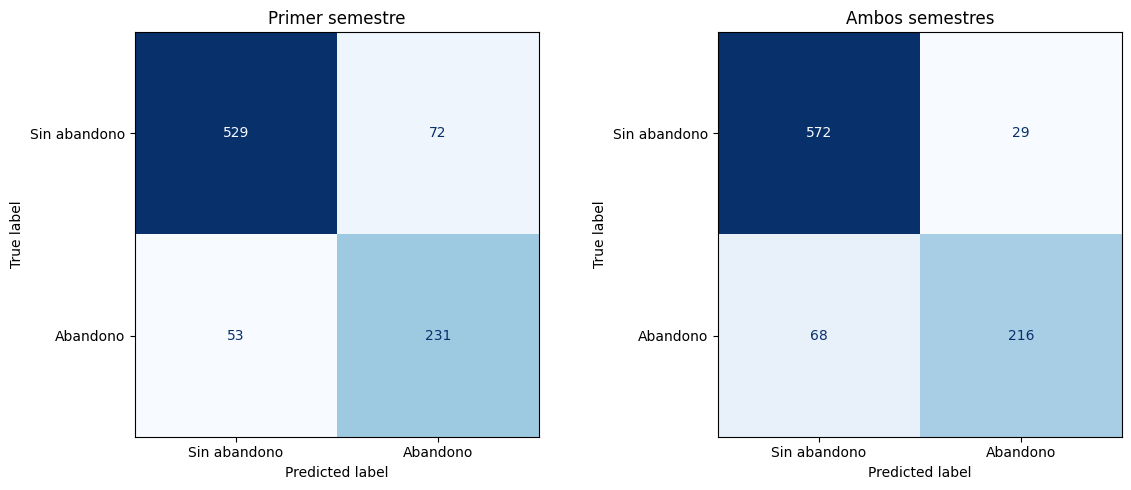

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, escenario in zip(
    axes,
    ["Primer semestre", "Ambos semestres"]
):
    predicciones = predicciones_finales[escenario]["clase"]

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Sin abandono", "Abandono"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(escenario)

    tn, fp, fn, tp = matriz.ravel()

    print(f"\n{escenario}")
    print("Sin abandono correctamente clasificados:", tn)
    print("Falsas alertas:", fp)
    print("Abandonos sin detectar:", fn)
    print("Abandonos detectados:", tp)

plt.tight_layout()
plt.show()

#Curvas ROC

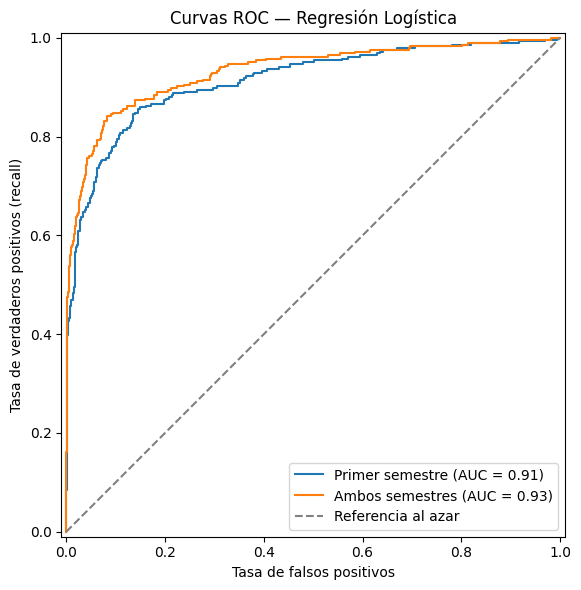

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))

for escenario in ["Primer semestre", "Ambos semestres"]:
    probabilidades = predicciones_finales[escenario]["probabilidad"]

    RocCurveDisplay.from_predictions(
        y_test,
        probabilidades,
        name=escenario,
        ax=ax
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia al azar"
)

ax.set_title("Curvas ROC — Regresión Logística")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

#SHAP para importancia de variables

In [ ]:
!pip install -q shap

In [ ]:
import shap

##Escenario contando notas del primer semestre

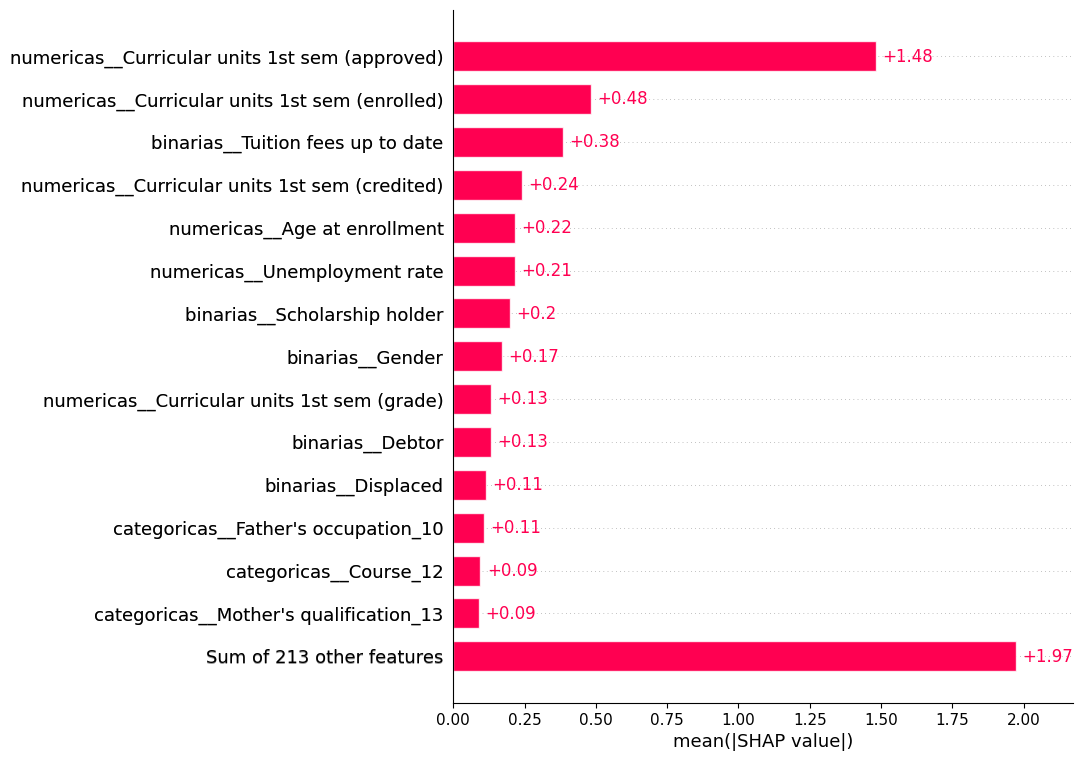

In [ ]:
pipeline_1 = modelos_finales["Primer semestre"]

preprocesador_1 = pipeline_1.named_steps["preprocesamiento"]
logistica_1 = pipeline_1.named_steps["modelo"]

nombres_1 = preprocesador_1.get_feature_names_out()

train_transformado_1 = pd.DataFrame(
    preprocesador_1.transform(X_train_1),
    columns=nombres_1,
    index=X_train_1.index
)

test_transformado_1 = pd.DataFrame(
    preprocesador_1.transform(X_test_1),
    columns=nombres_1,
    index=X_test_1.index
)

referencia_1 = shap.maskers.Independent(
    train_transformado_1,
    max_samples=len(train_transformado_1)
)

explainer_1 = shap.LinearExplainer(
    logistica_1,
    referencia_1
)

shap_values_1 = explainer_1(test_transformado_1)

# Importancia global: media del valor absoluto de SHAP.
shap.plots.bar(shap_values_1, max_display=15)

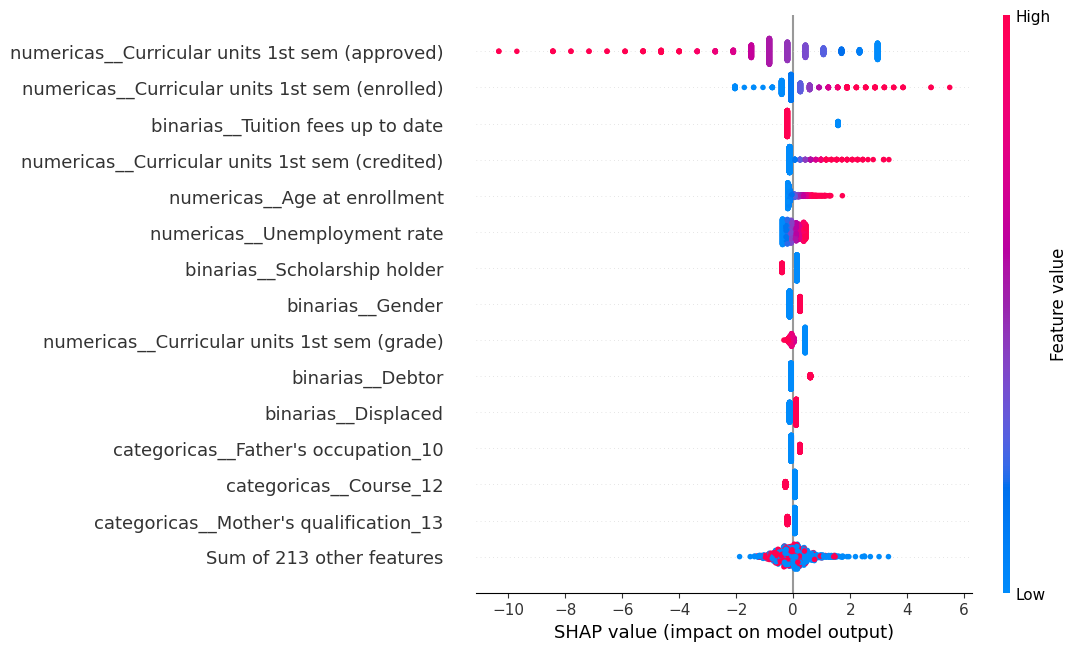

In [ ]:
shap.plots.beeswarm(shap_values_1, max_display=15)

##Escenario contando notas del primer y segundo semestre

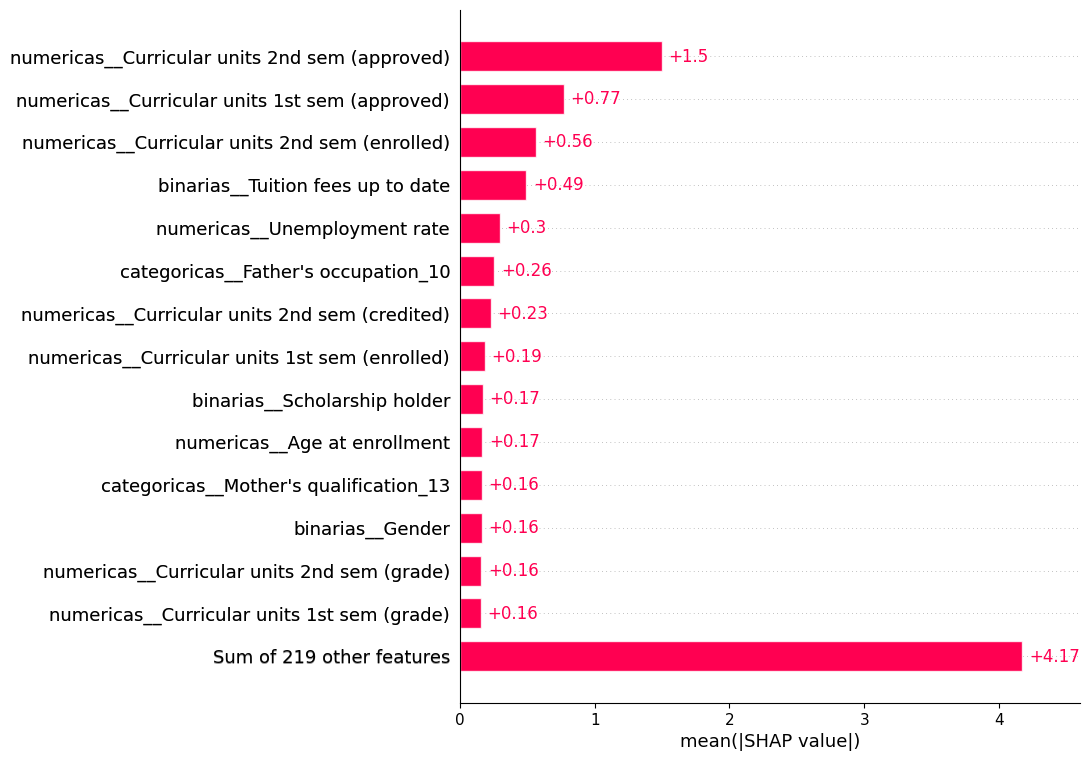

In [ ]:
pipeline_2 = modelos_finales["Ambos semestres"]

preprocesador_2 = pipeline_2.named_steps["preprocesamiento"]
logistica_2 = pipeline_2.named_steps["modelo"]

nombres_2 = preprocesador_2.get_feature_names_out()

train_transformado_2 = pd.DataFrame(
    preprocesador_2.transform(X_train_2),
    columns=nombres_2,
    index=X_train_2.index
)

test_transformado_2 = pd.DataFrame(
    preprocesador_2.transform(X_test_2),
    columns=nombres_2,
    index=X_test_2.index
)

referencia_2 = shap.maskers.Independent(
    train_transformado_2,
    max_samples=len(train_transformado_2)
)

explainer_2 = shap.LinearExplainer(
    logistica_2,
    referencia_2
)

shap_values_2 = explainer_2(test_transformado_2)

# Magnitud media de las contribuciones.
shap.plots.bar(shap_values_2, max_display=15)



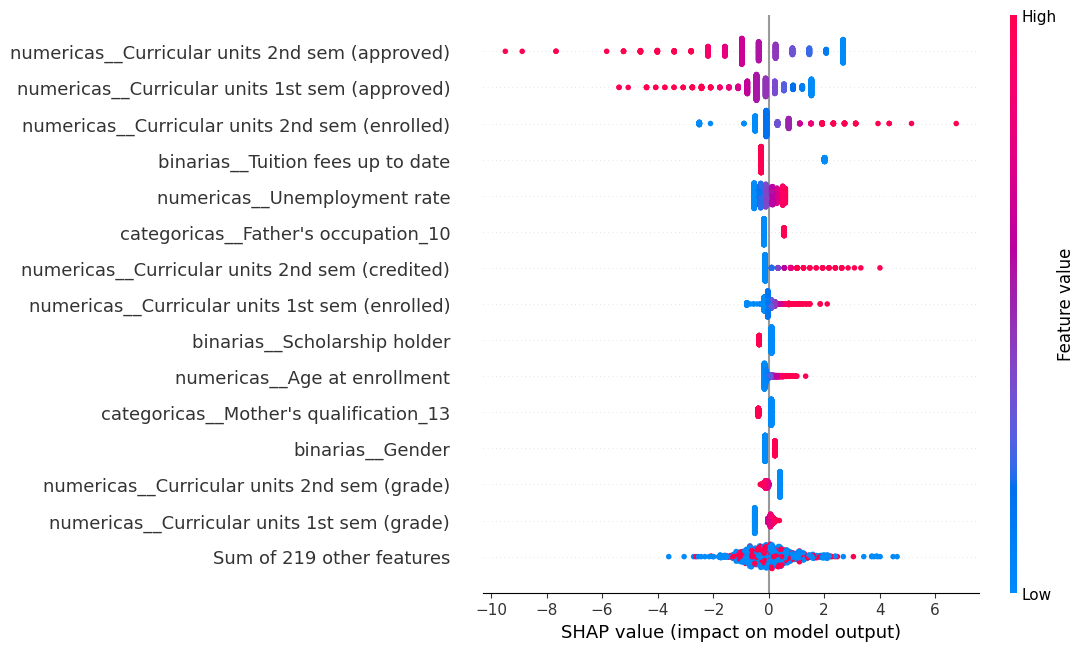

In [ ]:
# Dirección de las contribuciones.
shap.plots.beeswarm(shap_values_2, max_display=15)

In [ ]:
def agrupar_shap(valores_shap, preprocesador):
    variables_originales = []

    for nombre, transformador, columnas in preprocesador.transformers_:
        if nombre == "categoricas":
            for columna, categorias in zip(
                columnas, transformador.categories_
            ):
                variables_originales.extend(
                    [columna] * len(categorias)
                )

        elif nombre in ["numericas", "binarias"]:
            variables_originales.extend(columnas)

    assert len(variables_originales) == valores_shap.values.shape[1]

    contribuciones = pd.DataFrame(
        valores_shap.values,
        columns=variables_originales
    )

    # Sumamos primero los SHAP con su signo por variable.
    agrupadas = contribuciones.T.groupby(level=0, sort=False).sum().T

    importancia = (
        agrupadas.abs().mean()
        .sort_values(ascending=False)
        .rename("Media absoluta de SHAP agrupado")
        .to_frame()
    )

    return importancia


importancia_1 = agrupar_shap(shap_values_1, preprocesador_1)
importancia_2 = agrupar_shap(shap_values_2, preprocesador_2)

print("Primer semestre")
display(importancia_1.head(15).round(4))

print("\nAmbos semestres")
display(importancia_2.head(15).round(4))

Primer semestre


,Media absoluta de SHAP agrupado
Curricular units 1st sem (approved),1.4811
Curricular units 1st sem (enrolled),0.4831
Tuition fees up to date,0.3844
Course,0.2898
Curricular units 1st sem (credited),0.2407
Age at enrollment,0.2156
Unemployment rate,0.2147
Scholarship holder,0.1972
Application mode,0.1926
Gender,0.1705



Ambos semestres


,Media absoluta de SHAP agrupado
Curricular units 2nd sem (approved),1.4961
Curricular units 1st sem (approved),0.7727
Curricular units 2nd sem (enrolled),0.5631
Tuition fees up to date,0.4930
Course,0.3841
Unemployment rate,0.2976
Mother's qualification,0.2655
Application mode,0.2580
Curricular units 2nd sem (credited),0.2302
Father's occupation,0.2176


#MODELOS

<Axes: >

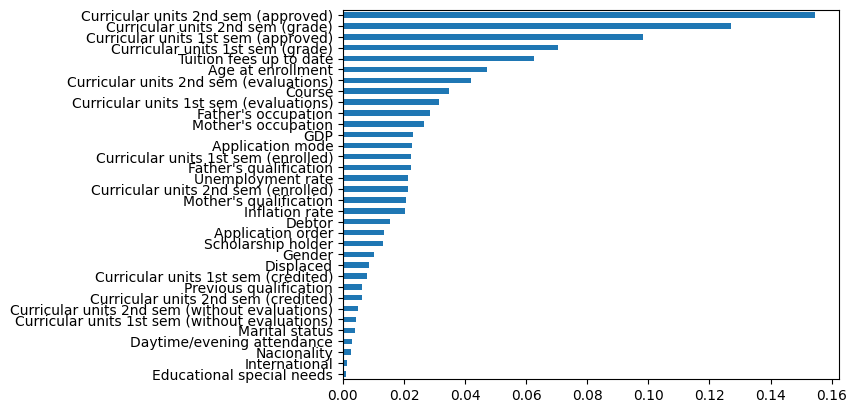

In [ ]:
importancias_rf.sort_values().plot(kind="barh")